# 07 — Interpretation and per-crisis results

*CRISP-DM phase 5 · code: `interpret_models.py`*

What drives the predictions (logistic-regression coefficients, LightGBM SHAP values) and how each method did in every stress crisis and bear market of 1980–2021. Uses the walk-forward predictions from notebook 05.

← previous: [`06_feature_groups.ipynb`](06_feature_groups.ipynb) · next: [`08_holdout.ipynb`](08_holdout.ipynb) →

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]   # project package + root scripts

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "font.size": 10})

In [2]:
def run_script(module, *args):
    """Run a project script's main() exactly as on the command line, then restore inline plots."""
    import importlib
    mod = importlib.import_module(module)
    old = sys.argv
    sys.argv = [f"{module}.py", *args]
    try:
        code = mod.main()
    finally:
        sys.argv = old
    get_ipython().run_line_magic("matplotlib", "inline")
    return code

In [3]:
run_script("interpret_models")

[18:27:11] 1/3 Logistic regression coefficients


[18:27:12]   logistic regression stressed: fitted on 14,780 rows, 42 folds


[18:27:13]   logistic regression bear: fitted on 14,780 rows, 42 folds


[18:27:13] 2/3 LightGBM SHAP


[18:27:17]   LightGBM stressed: SHAP on 14,780 rows


[18:27:20]   LightGBM bear: SHAP on 14,780 rows


[18:27:21] 3/3 Per-crisis results


[18:27:22] wrote reports/interpretation.md, docs/figures/interp_logreg_coefficients.png, interp_lightgbm_shap.png



== stressed: logistic coefficients
                   coef  same_sign_share
rv_vs_5y_p80       1.98             1.00
rv_21d            -1.23             0.93
rv_63d             0.87             0.98
below_peak_regime -0.66             1.00
dist_ma50         -0.56             1.00
parkinson_21d      0.46             1.00
mom_3m             0.32             1.00
mom_1m            -0.26             1.00
ret_1d            -0.15             1.00
dist_ma200         0.13             0.74
mom_12m            0.05             0.48
drawdown          -0.03             0.43
gap_open           0.00             1.00
== stressed: LightGBM SHAP
                   mean_abs_shap  direction
rv_vs_5y_p80               0.904      0.973
dist_ma200                 0.306     -0.344
drawdown                   0.283      0.833
rv_63d                     0.215      0.761
dist_ma50                  0.196     -0.584
rv_21d                     0.192     -0.822
parkinson_21d              0.189      0.796
mom_1m     

0

## 1. Logistic regression coefficients

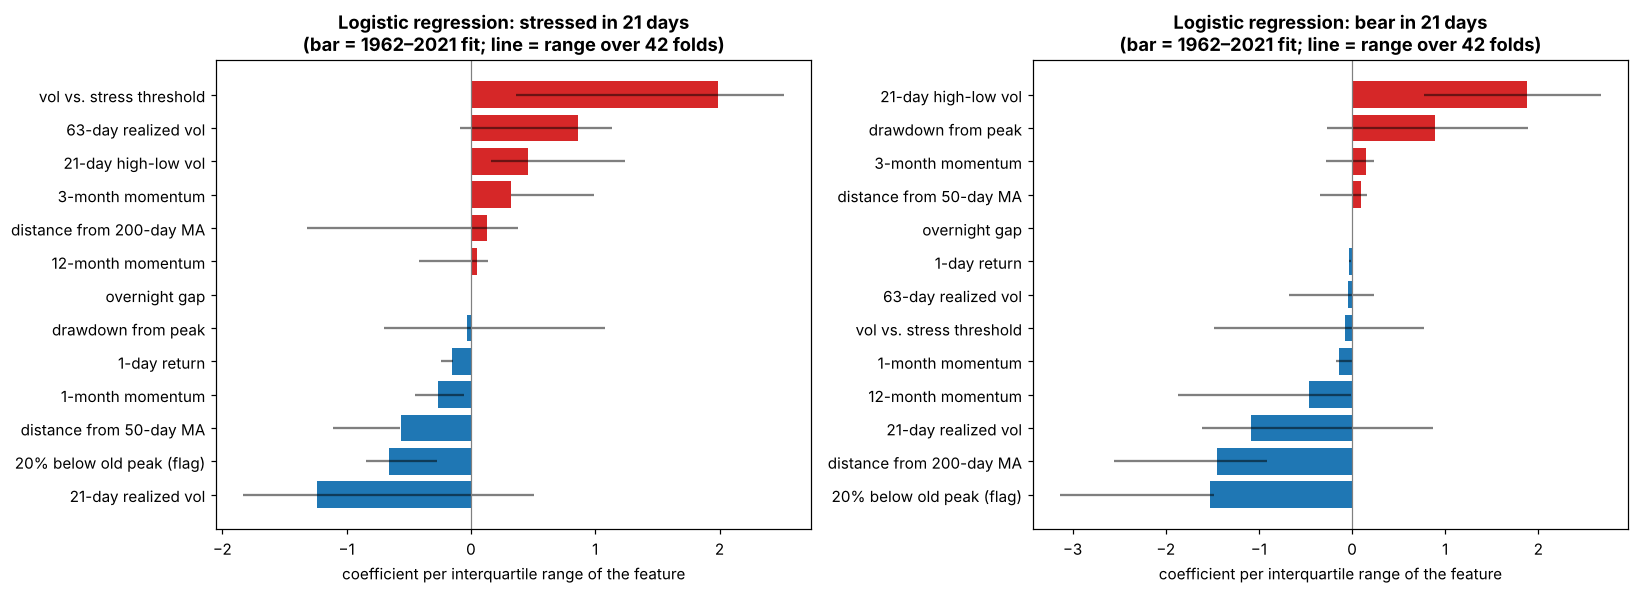

In [4]:
display(Image(ROOT / "docs" / "figures" / "interp_logreg_coefficients.png"))

## 2. LightGBM SHAP

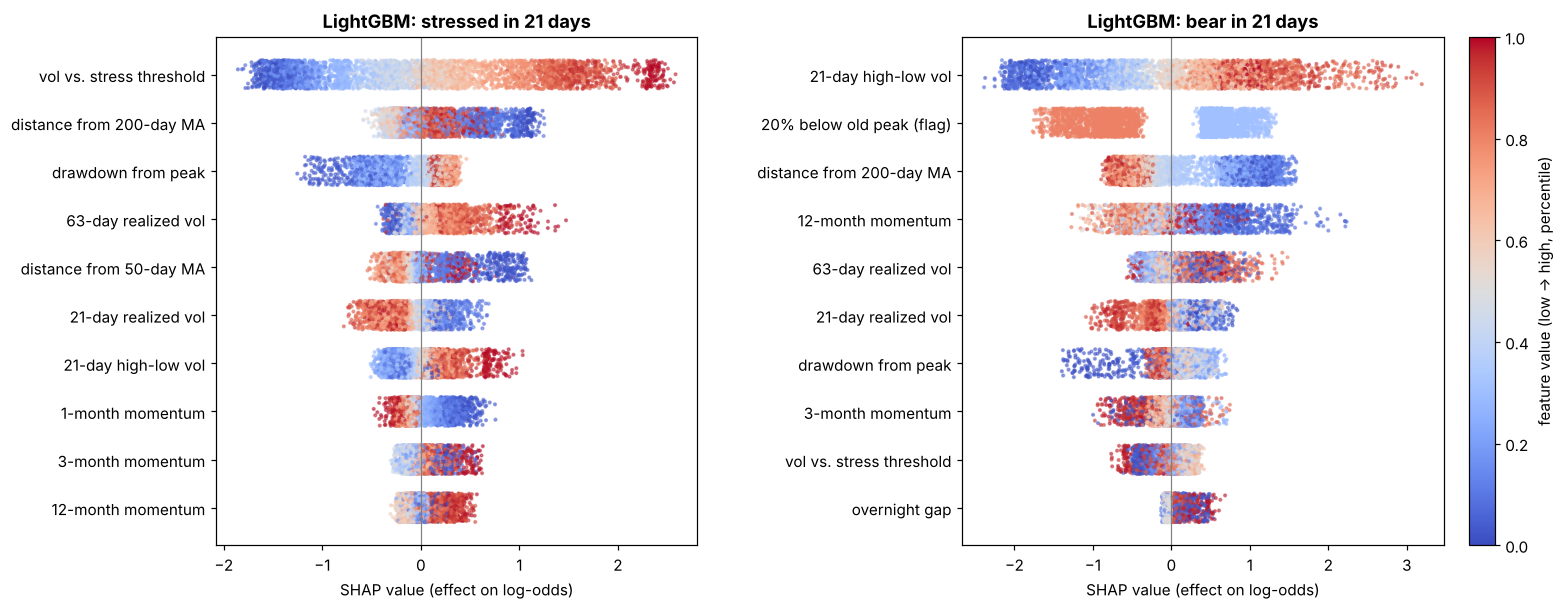

In [5]:
display(Image(ROOT / "docs" / "figures" / "interp_lightgbm_shap.png"))

## 3. Full report (tables and per-crisis results)

In [6]:
display(Markdown((ROOT / "reports" / "interpretation.md").read_text().replace("../docs/figures/", str(ROOT / "docs" / "figures") + "/")))

# Model interpretation and per-crisis results

Generated 2026-11-25 18:27 by `interpret_models.py`. Horizon: 21 trading days. Final fits use 1962–2021 (bear labels recomputed with prices up to 2021-12-31); per-crisis results use the out-of-sample walk-forward predictions from `run_models.py`. The 2022+ holdout is not used.

## 1. Logistic regression coefficients

Features are robust-scaled, so a coefficient is the change in log-odds when the feature moves by one interquartile range (IQR). Odds ratio = exp(coef). *Same sign* = share of the walk-forward refits (one per test year) with the same sign as the final fit.

![Logistic regression coefficients](/home/claude/repo/sp500-regime-prediction/docs/figures/interp_logreg_coefficients.png)

### `stressed` in 21 days (42 folds)

| Feature | Coef | Odds ratio per IQR | Range over folds | Same sign |
|---|---|---|---|---|
| vol vs. stress threshold (`rv_vs_5y_p80`) | +1.98 | 7.27 | +0.37 to +2.52 | 100% |
| 21-day realized vol (`rv_21d`) | -1.23 | 0.29 | -1.83 to +0.51 | 93% |
| 63-day realized vol (`rv_63d`) | +0.87 | 2.38 | -0.08 to +1.14 | 98% |
| 20% below old peak (flag) (`below_peak_regime`) | -0.66 | 0.52 | -0.84 to -0.27 | 100% |
| distance from 50-day MA (`dist_ma50`) | -0.56 | 0.57 | -1.11 to -0.57 | 100% |
| 21-day high-low vol (`parkinson_21d`) | +0.46 | 1.58 | +0.16 to +1.24 | 100% |
| 3-month momentum (`mom_3m`) | +0.32 | 1.38 | +0.32 to +0.99 | 100% |
| 1-month momentum (`mom_1m`) | -0.26 | 0.77 | -0.45 to -0.06 | 100% |
| 1-day return (`ret_1d`) | -0.15 | 0.86 | -0.24 to -0.14 | 100% |
| distance from 200-day MA (`dist_ma200`) | +0.13 | 1.14 | -1.32 to +0.38 | 74% |
| 12-month momentum (`mom_12m`) | +0.05 | 1.05 | -0.42 to +0.14 | 48% |
| drawdown from peak (`drawdown`) | -0.03 | 0.97 | -0.70 to +1.08 | 43% |
| overnight gap (`gap_open`) | +0.00 | 1.00 | +0.00 to +0.01 | 100% |

### `bear` in 21 days (42 folds)

| Feature | Coef | Odds ratio per IQR | Range over folds | Same sign |
|---|---|---|---|---|
| 21-day high-low vol (`parkinson_21d`) | +1.87 | 6.51 | +0.77 to +2.67 | 100% |
| 20% below old peak (flag) (`below_peak_regime`) | -1.52 | 0.22 | -3.14 to -1.48 | 100% |
| distance from 200-day MA (`dist_ma200`) | -1.45 | 0.24 | -2.56 to -0.91 | 100% |
| 21-day realized vol (`rv_21d`) | -1.08 | 0.34 | -1.61 to +0.87 | 95% |
| drawdown from peak (`drawdown`) | +0.89 | 2.42 | -0.27 to +1.89 | 74% |
| 12-month momentum (`mom_12m`) | -0.46 | 0.63 | -1.87 to -0.01 | 100% |
| 3-month momentum (`mom_3m`) | +0.15 | 1.16 | -0.28 to +0.24 | 50% |
| 1-month momentum (`mom_1m`) | -0.14 | 0.87 | -0.18 to -0.01 | 100% |
| distance from 50-day MA (`dist_ma50`) | +0.09 | 1.10 | -0.34 to +0.16 | 36% |
| vol vs. stress threshold (`rv_vs_5y_p80`) | -0.08 | 0.93 | -1.48 to +0.78 | 79% |
| 63-day realized vol (`rv_63d`) | -0.04 | 0.96 | -0.68 to +0.24 | 62% |
| 1-day return (`ret_1d`) | -0.03 | 0.97 | -0.03 to -0.01 | 100% |
| overnight gap (`gap_open`) | +0.00 | 1.00 | -0.00 to +0.00 | 79% |

## 2. LightGBM SHAP

Mean |SHAP| = average size of the feature's effect on the log-odds. *Direction* = rank correlation between the feature value and its SHAP value (+ means higher value → higher probability).

![LightGBM SHAP](/home/claude/repo/sp500-regime-prediction/docs/figures/interp_lightgbm_shap.png)

**By feature group** (share of total mean |SHAP|; correlated features within a group share credit):

| Group | `stressed` in 21 days | `bear` in 21 days |
|---|---|---|
| Volatility | 51% | 41% |
| Trend / momentum | 30% | 33% |
| Drawdown | 13% | 24% |
| Daily moves | 6% | 2% |

### `stressed` in 21 days

| Rank | Feature | Mean \|SHAP\| | Share | Direction |
|---|---|---|---|---|
| 1 | vol vs. stress threshold (`rv_vs_5y_p80`) | 0.904 | 31% | +0.97 |
| 2 | distance from 200-day MA (`dist_ma200`) | 0.306 | 10% | -0.34 |
| 3 | drawdown from peak (`drawdown`) | 0.283 | 10% | +0.83 |
| 4 | 63-day realized vol (`rv_63d`) | 0.215 | 7% | +0.76 |
| 5 | distance from 50-day MA (`dist_ma50`) | 0.196 | 7% | -0.58 |
| 6 | 21-day realized vol (`rv_21d`) | 0.192 | 6% | -0.82 |
| 7 | 21-day high-low vol (`parkinson_21d`) | 0.189 | 6% | +0.80 |
| 8 | 1-month momentum (`mom_1m`) | 0.146 | 5% | -0.82 |
| 9 | 3-month momentum (`mom_3m`) | 0.129 | 4% | +0.24 |
| 10 | 12-month momentum (`mom_12m`) | 0.125 | 4% | +0.43 |
| 11 | 20% below old peak (flag) (`below_peak_regime`) | 0.100 | 3% | -0.93 |
| 12 | 1-day return (`ret_1d`) | 0.099 | 3% | -0.81 |
| 13 | overnight gap (`gap_open`) | 0.079 | 3% | -0.15 |

### `bear` in 21 days

| Rank | Feature | Mean \|SHAP\| | Share | Direction |
|---|---|---|---|---|
| 1 | 21-day high-low vol (`parkinson_21d`) | 0.942 | 25% | +0.93 |
| 2 | 20% below old peak (flag) (`below_peak_regime`) | 0.731 | 19% | -0.94 |
| 3 | distance from 200-day MA (`dist_ma200`) | 0.583 | 15% | -0.89 |
| 4 | 12-month momentum (`mom_12m`) | 0.413 | 11% | -0.55 |
| 5 | 63-day realized vol (`rv_63d`) | 0.254 | 7% | +0.13 |
| 6 | 21-day realized vol (`rv_21d`) | 0.202 | 5% | -0.67 |
| 7 | drawdown from peak (`drawdown`) | 0.181 | 5% | -0.01 |
| 8 | 3-month momentum (`mom_3m`) | 0.173 | 5% | -0.44 |
| 9 | vol vs. stress threshold (`rv_vs_5y_p80`) | 0.171 | 4% | +0.14 |
| 10 | overnight gap (`gap_open`) | 0.073 | 2% | +0.04 |
| 11 | distance from 50-day MA (`dist_ma50`) | 0.070 | 2% | -0.49 |
| 12 | 1-month momentum (`mom_1m`) | 0.025 | 1% | -0.48 |
| 13 | 1-day return (`ret_1d`) | 0.001 | 0% | -0.40 |

## 3. Per-crisis results (out-of-sample)

### Stress episodes (21-day predictions)

Signal start relative to the first stressed day, in trading days: **negative = warned in advance**, +k = recognized k days after stress began, *missed* = no ≥ 50% signal within 42 days. *P before* = mean predicted probability over the 21 trading days before stress began.

| Crisis | Stress start | Max drawdown | No change | HMM | Logistic | LightGBM | P before (Logistic / LightGBM) |
|---|---|---|---|---|---|---|---|
| 1987 crash | 1987-09-01 | -34% | +0 | +0 | +24 | +30 | 0.08 / 0.20 |
| 1990 Gulf War | 1990-08-08 | -20% | +0 | missed | -2 | -2 | 0.28 / 0.14 |
| 1997 Asian crisis | 1997-10-21 | -11% | +0 | missed | +2 | +4 | 0.47 / 0.56 |
| 1998 LTCM / Russia | 1998-07-30 | -19% | +0 | missed | +1 | +3 | 0.22 / 0.39 |
| 2000 dot-com top | 2000-03-01 | -11% | -36 | missed | +4 | +4 | 0.38 / 0.38 |
| 2001 9/11 | 2001-09-17 | -37% | +0 | -3 | +3 | -7 | 0.07 / 0.46 |
| 2002 accounting scandals | 2002-06-03 | -49% | +0 | +0 | +26 | +0 | 0.17 / 0.37 |
| 2007 subprime start | 2007-07-27 | -9% | +0 | -1 | +2 | +2 | 0.17 / 0.13 |
| 2008 Lehman | 2008-09-02 | -52% | ≤ -42 | -2 | +2 | +2 | 0.43 / 0.35 |
| 2010 flash crash / euro | 2010-05-10 | -35% | +0 | -4 | +8 | +8 | 0.06 / 0.04 |
| 2011 US downgrade | 2011-08-08 | -30% | +0 | -2 | +0 | -2 | 0.07 / 0.12 |
| 2015 China devaluation | 2015-08-21 | -12% | +0 | +0 | +0 | +0 | 0.12 / 0.05 |
| 2018 Volmageddon | 2018-02-05 | -10% | +0 | +0 | +0 | +3 | 0.03 / 0.06 |
| 2018 Q4 sell-off | 2018-10-12 | -20% | +0 | -2 | +4 | +4 | 0.07 / 0.04 |
| 2020 COVID | 2020-02-24 | -34% | +0 | +0 | +1 | +1 | 0.08 / 0.17 |

### Bear markets (21-day predictions)

When did each method first say ≥ 50% "bear within 21 days", counted from the market peak, and how far had the market already fallen by then? *on at peak* = the signal was still on from before.

| Bear (peak → trough) | Fall | No change | MA200 rule | HMM | Logistic | LightGBM |
|---|---|---|---|---|---|---|
| 1980-11-28 → 1982-08-12 | -27% | never | +108d (-7%) | +1d (-2%) | +136d (-5%) | +37d (-7%) |
| 1987-08-25 → 1987-12-04 | -34% | +38d (-33%) | +36d (-11%) | +5d (-4%) | +43d (-32%) | +37d (-16%) |
| 2000-09-01 → 2001-09-21 | -36% | +130d (-22%) | +10d (-5%) | +83d (-16%) | +27d (-10%) | +27d (-10%) |
| 2002-03-19 → 2002-07-23 | -32% | on at peak | +4d (-3%) | +19d (-4%) | +78d (-21%) | +75d (-15%) |
| 2007-10-09 → 2008-11-20 | -52% | +191d (-22%) | +21d (-6%) | +8d (-4%) | +71d (-16%) | +72d (-14%) |
| 2009-01-06 → 2009-03-09 | -28% | on at peak | on at peak | +1d (-3%) | +0d (0%) | never |
| 2020-02-19 → 2020-03-23 | -34% | +16d (-27%) | +6d (-12%) | +3d (-5%) | never | +18d (-30%) |
